# Strait of Georgia: precision-recall curves for every model

Loads every model's per-clip test scores and draws one PR curve per model, averaged over the 5 folds. The fine-tuned arms and Perch come from their MLflow runs, the off-the-shelf detectors from experiment `hallo_tuned_detectors_comparison`. The exp_2 zero-shot scores are not in MLflow; they are read from `adabn_exp3_predictions.csv`. Needs the MLflow server at localhost:5000.

In [6]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve

ADAPT = Path("../scripts/adaptation").resolve()
sys.path.insert(0, str(ADAPT))
import compare_tuned_detectors as ctd  # reuse its loaders so the clips and scores match the summary table

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # no download progress bars
SITE = "strait_of_georgia"
mlflow.set_tracking_uri(ctd.TRACKING_URI)

## Load the predictions
One row per (model, fold, clip) with `split`, `true_label` and the score columns.

In [7]:
# fine-tuned arms + Perch probe (MLflow)
arms = ctd.comparison_predictions([], {p: m for p, m in ctd.COMPARISON_RUNS.items() if m in ctd.ARMS})
# exp_2 zero-shot EffNet-B1 (csv, not in MLflow)
zs = pd.read_csv(ADAPT / "results/exp3_splits/adabn_exp3_predictions.csv")
zs = zs[(zs.variant == "zeroshot") & (zs.model == "effnet_b1")].rename(columns={"variant": "method"})
arms = ctd.restrict_to_folds(pd.concat([arms, zs]))
arms = arms[arms.site == SITE]

# off-the-shelf detectors (MLflow), copied onto the same fold / split rows as the arms
folds = arms[arms.method == "effnet_b1_ft"][["uid", "fold", "split", "true_label"]]
det, _ = ctd.detector_scores(SITE, None)
preds = pd.concat([arms, ctd.detector_predictions(det, folds)], ignore_index=True)

test = preds[preds.split == "test"]
test.groupby("method").uid.count()

method
birdnet                  12960
cascade                  12960
effnet_b1_ft             12960
hallo_v1                 12960
perch_v2_probe           12960
sequence                 12960
ssamba_A_supervised      12960
ssamba_B_ssl_source      12960
ssamba_C5_ssl_all_5ep    12960
ssamba_D_scratch         12960
zeroshot                 12960
Name: uid, dtype: int64

## Plot
`task` is `"SRKW"` (SRKW vs rest) or `"KW"` (SRKW + TKW vs rest).  `SHOW` picks the models. Each curve is the mean of the 5 folds' test curves; the legend gives the mean PR-AUC.

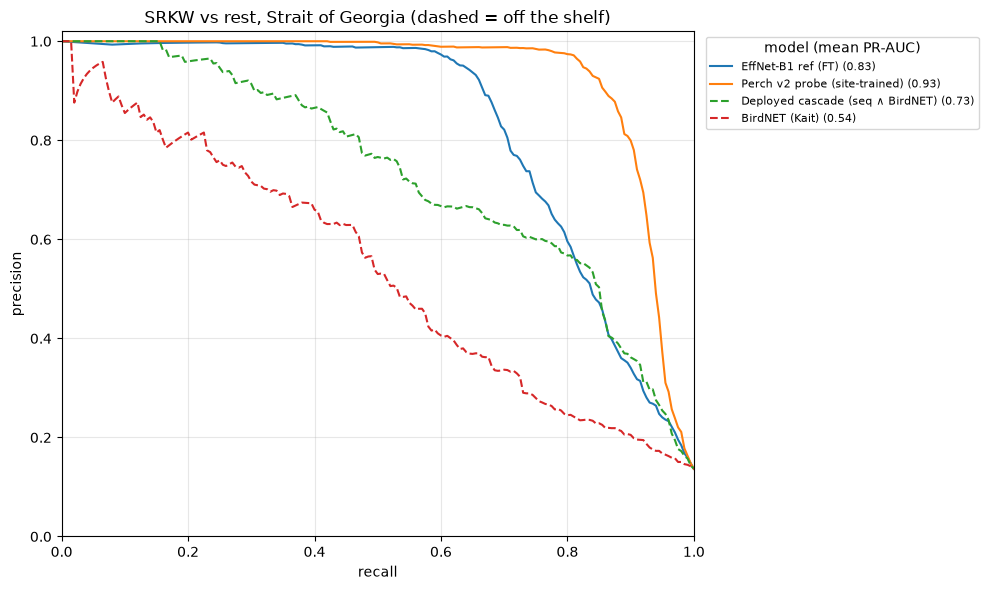

In [8]:
SHOW = [
        "effnet_b1_ft", 
        "perch_v2_probe", 
        "cascade", 
       #  "sequence", 
        "birdnet"
        ]  # models to plot; any keys of ctd.LABELS

def plot_pr(task):
    positive = {"SRKW"} if task == "SRKW" else {"SRKW", "TKW"}
    recall_grid = np.linspace(0, 1, 201)
    fig, ax = plt.subplots(figsize=(10, 6))
    for method in SHOW:
        label = ctd.LABELS[method]
        curves, aps = [], []
        for _, p in test[test.method == method].groupby("fold"):
            score = (p.prob_SRKW if task == "SRKW" else ctd.kw_score(p)).to_numpy()
            y = p.true_label.isin(positive).to_numpy()
            precision, recall, _ = precision_recall_curve(y, score)
            curves.append(np.interp(recall_grid, recall[::-1], precision[::-1]))
            aps.append(average_precision_score(y, score))
        if curves:
            ax.plot(recall_grid, np.mean(curves, axis=0), label=f"{label} ({np.mean(aps):.2f})",
                    linestyle="--" if method in ctd.OFF_THE_SHELF else "-")
    ax.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02),
           title=f"{task} vs rest, Strait of Georgia (dashed = off the shelf)")
    ax.legend(title="model (mean PR-AUC)", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

plot_pr("SRKW")

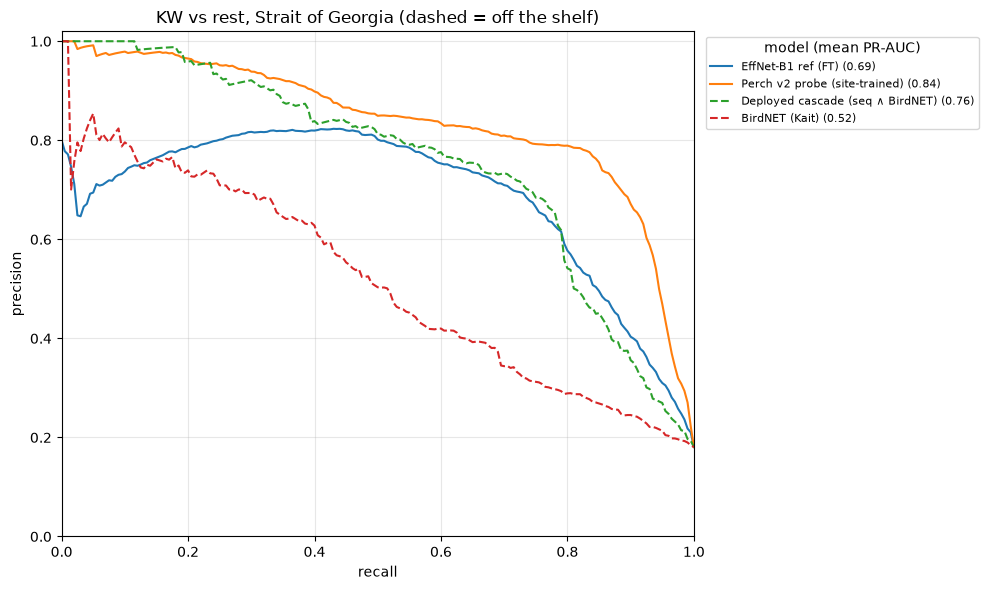

In [9]:
plot_pr("KW")